In [175]:
import sklearn, pandas
print(sklearn.__version__, pandas.__version__)

import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV

import matplotlib.pyplot as plt


1.9.1 3.0.6


In [176]:
train = pd.read_csv("../train.csv")
test = pd.read_csv("../test.csv")

print(train.shape, test.shape)


(105, 6) (45, 5)


In [177]:
train.head()


,id,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,81,5.5,2.4,3.7,1.0,1
1,133,6.3,2.8,5.1,1.5,2
2,137,6.4,3.1,5.5,1.8,2
3,75,6.6,3.0,4.4,1.4,1
4,109,7.2,3.6,6.1,2.5,2


In [178]:
train["target"].value_counts()


target
1    37
2    37
0    31
Name: count, dtype: int64

In [179]:
train.isna().sum()


id                   0
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

In [180]:
X = train.drop(columns=["id", "target"])
y = train["target"]

X_test = test.drop(columns=["id"])
test_ids = test["id"]

print(X_test.shape)

print(X.shape, y.shape)
print(list(X.columns) == list(X_test.columns))


(45, 4)
(105, 4) (105,)
True


In [181]:
model = make_pipeline(StandardScaler(), SVC(kernel="rbf"))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")

print(scores)
print(f"Mean accuracy: {scores.mean():.3f} ± {scores.std():.3f}")


[0.95238095 0.95238095 0.95238095 0.9047619  0.95238095]
Mean accuracy: 0.943 ± 0.019


In [182]:
param_grid = {
    "svc__C": [0.1, 1, 10, 100, 1000],
    "svc__gamma": ["scale", 0.001, 0.01, 0.1, 1],
}


In [183]:
search = GridSearchCV(model, param_grid, cv=cv, scoring="accuracy")
search.fit(X, y)

print("Best params:", search.best_params_)
print(f"Best CV accuracy: {search.best_score_:.3f}")


Best params: {'svc__C': 100, 'svc__gamma': 0.01}
Best CV accuracy: 0.971


In [184]:
results = pd.DataFrame(search.cv_results_)
results[["param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False)


,param_svc__C,param_svc__gamma,mean_test_score,std_test_score
17,100.0,0.01,0.971429,0.023328
21,1000.0,0.001,0.961905,0.019048
10,10.0,scale,0.961905,0.019048
12,10.0,0.01,0.952381,0.030117
13,10.0,0.1,0.952381,0.030117
22,1000.0,0.01,0.952381,0.030117
16,100.0,0.001,0.952381,0.030117
5,1.0,scale,0.942857,0.019048
18,100.0,0.1,0.933333,0.023328
8,1.0,0.1,0.933333,0.023328


In [185]:
predictions = search.predict(X_test)
predictions


array([1, 0, 2, 1, 1, 0, 1, 2, 2, 1, 2, 0, 0, 0, 0, 1, 2, 1, 1, 2, 0, 2,
       0, 2, 2, 2, 2, 2, 0, 0, 0, 0, 1, 0, 0, 2, 1, 0, 0, 0, 2, 1, 1, 0,
       0])

In [186]:
submission = pd.DataFrame({"id": test_ids, "target": predictions})
submission.to_csv("SVMtest.csv", index=False)
submission.head()

,id,target
0,73,1
1,18,0
2,118,2
3,78,1
4,76,1


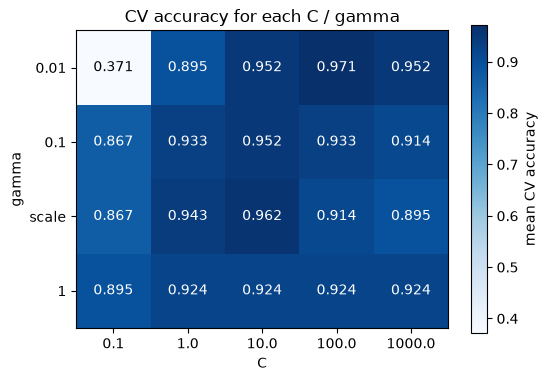

In [187]:
results["gamma"] = results["param_svc__gamma"].astype(str)
table = results.pivot(index="gamma", columns="param_svc__C", values="mean_test_score")
table = table.loc[["0.01", "0.1", "scale", "1"]]

fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(table, cmap="Blues")
ax.set_xticks(range(len(table.columns)), table.columns)
ax.set_yticks(range(len(table.index)), table.index)
ax.set_xlabel("C")
ax.set_ylabel("gamma")
mid = (table.values.min() + table.values.max()) / 2
for i in range(len(table.index)):
    for j in range(len(table.columns)):
        v = table.iloc[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v > mid else "black")
fig.colorbar(im, label="mean CV accuracy")
ax.set_title("CV accuracy for each C / gamma")
plt.show()